In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [6]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [13]:
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('unknown')

In [14]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               0
babies                                 0
meal                                   0
country                                0
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [24]:
df.groupby('hotel')['is_canceled'].value_counts()

hotel         is_canceled
City Hotel    0              46228
              1              33102
Resort Hotel  0              28938
              1              11122
Name: count, dtype: int64

In [25]:
months_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=months_order, ordered=True)

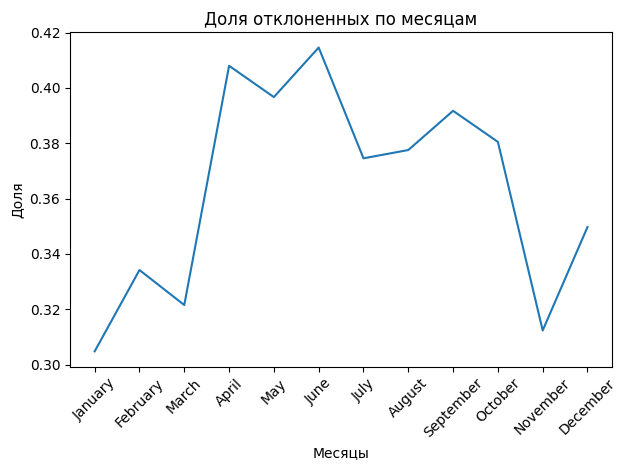

In [35]:
df.groupby('arrival_date_month')['is_canceled'].mean().plot(kind = 'line')
plt.title('Доля отклоненных по месяцам')
plt.xlabel('Месяцы')
plt.ylabel('Доля')
plt.xticks(range(12), months_order, rotation=45)
plt.tight_layout()
plt.show()

Видим, что к летнему сезону доля отмен возрастает

In [38]:
df[df['children'] > 0]['is_canceled'].mean()

0.3639115250291036

In [39]:
df[df['children'] == 0]['is_canceled'].mean()

0.3709205776173285

Отмены практически одинаковые при наличии детей и нет

(array([0, 1, 2, 3, 4, 5, 6]),
 [Text(0, 0, 'Aviation'),
  Text(1, 0, 'Complementary'),
  Text(2, 0, 'Corporate'),
  Text(3, 0, 'Direct'),
  Text(4, 0, 'Groups'),
  Text(5, 0, 'Offline TA/TO'),
  Text(6, 0, 'Online TA')])

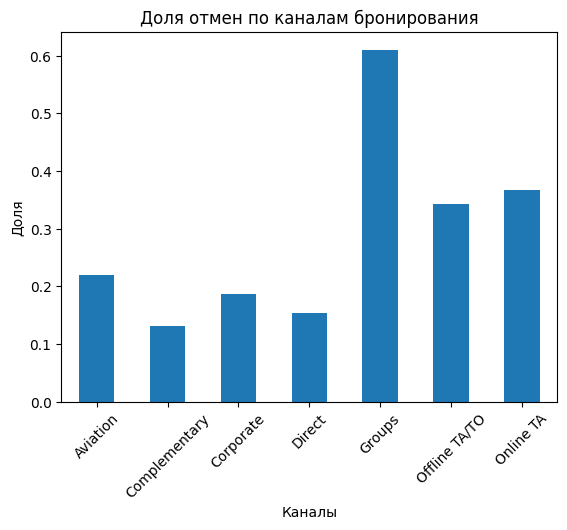

In [47]:
df[df['market_segment'] != 'Undefined'].groupby('market_segment')['is_canceled'].mean().plot(kind = 'bar')
plt.title('Доля отмен по каналам бронирования')
plt.xlabel('Каналы')
plt.ylabel('Доля')
plt.xticks(rotation = 45)

Видим что в канале Groups заметно выше доля отмен. 
Можно выдвинуть теорию, что H1: Доля отмен в канале groups выше чем в остальных каналах вместе
H0: Доля отмен одинаковая

In [48]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df['market_segment'], df['is_canceled'])
chi2, p_value, dof, expected = chi2_contingency(contingency_table)
print(f"p-value: {p_value:.4f}")

p-value: 0.0000


In [56]:
groups_data = df[df['market_segment'] == 'Groups']['is_canceled']
others_data = df[df['market_segment'] != 'Groups']['is_canceled']
x1 = groups_data.sum()
n1 = len(groups_data) 
x2 = others_data.sum()  
n2 = len(others_data)  
print(f"Groups: {x1} отмен из {n1} броней ({x1/n1:.2%})")
print(f"Others: {x2} отмен из {n2} броней ({x2/n2:.2%})")

Groups: 12097 отмен из 19811 броней (61.06%)
Others: 32127 отмен из 99579 броней (32.26%)


In [58]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
stat, p_value = proportions_ztest(
    count=[x1, x2], 
    nobs=[n1, n2], 
    alternative='larger'
)

print(f"\nZ-статистика: {stat:.2f}")
print(f"P-value (односторонний): {p_value:.4e}")

# 95% доверительный интервал для разницы долей
ci_low, ci_upp = confint_proportions_2indep(x1, n1, x2, n2, method='wald')
print(f"95% ДИ разницы: [{ci_low:.1%}, {ci_upp:.1%}]")


Z-статистика: 76.66
P-value (односторонний): 0.0000e+00
95% ДИ разницы: [28.1%, 29.5%]


Доля отмен в канале бронирования Groups составляет примерно 61%, в то время как в остальных каналах — около 32%. Разница в 29 п.п.
95% доверительный интервал для разницы: [28.1%, 29.5%].
z-тест п подтверждает, что доля отмен в Groups статистически значимо выше, чем в остальных каналах (Z = 76.66, p < 0.001). 
Имеет смысл обратить внимание на этот канал

In [64]:
df.groupby('deposit_type')['is_canceled'].value_counts()

deposit_type  is_canceled
No Deposit    0              74947
              1              29694
Non Refund    1              14494
              0                 93
Refundable    0                126
              1                 36
Name: count, dtype: int64

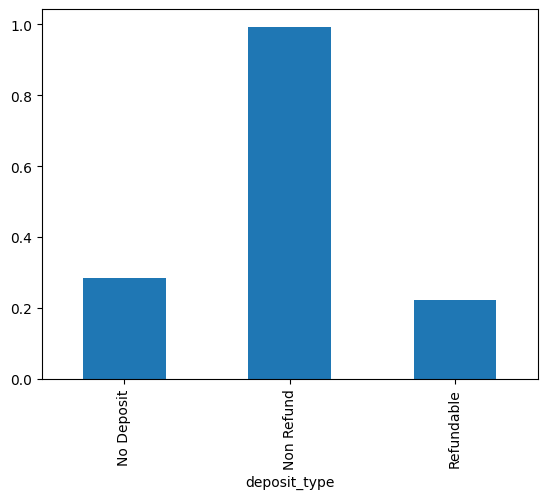

In [63]:
df.groupby('deposit_type')['is_canceled'].mean().plot(kind = 'bar')
plt.show()

Брони с невозвратным тарифом возвращаются почти в 100% случаев. Это странная ситуация, наверно проблема в датасете

In [77]:
print(f"Доля отмен без броней с типом Non Refund = {df[df['deposit_type'] != 'Non Refund']['is_canceled'].mean():.2}")


Доля отмен без броней с типом Non Refund = 0.28


In [78]:
print(f"Доля всех отмен = {df['is_canceled'].mean():.2}")

Доля всех отмен = 0.37


Уберем пока эти аномальные данные

In [98]:
df_without_NonRefund = df[df['deposit_type'] != 'Non Refund']

In [100]:
df_without_NonRefund.groupby('is_canceled')['lead_time'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
is_canceled,,,,,,,,
0,75073.0,80.0,91.1,0.0,9.0,45.0,124.0,737.0
1,29730.0,111.3,94.0,0.0,35.0,86.0,169.0,518.0


In [101]:
bins = [0, 7, 30, 90, 180, 365, df['lead_time'].max()]
labels = ['0-7 дней', '8-30 дней', '31-90 дней', '91-180 дней', '181-365 дней', '365+ дней']
df_without_NonRefund['lead_time_group'] = pd.cut(df_without_NonRefund['lead_time'], bins=bins, labels=labels, include_lowest=True)

In [102]:
result = df_without_NonRefund.groupby('lead_time_group', observed=True).agg(
    доля_отмен=('is_canceled', 'mean'),
    количество=('is_canceled', 'count')
).round(3)
result['доля_отмен'] = (result['доля_отмен'] * 100).round(1)

print(result)

                 доля_отмен  количество
lead_time_group                        
0-7 дней                9.2       19625
8-30 дней              26.0       18466
31-90 дней             32.2       27147
91-180 дней            34.8       22352
181-365 дней           39.8       15930
365+ дней              20.7        1283


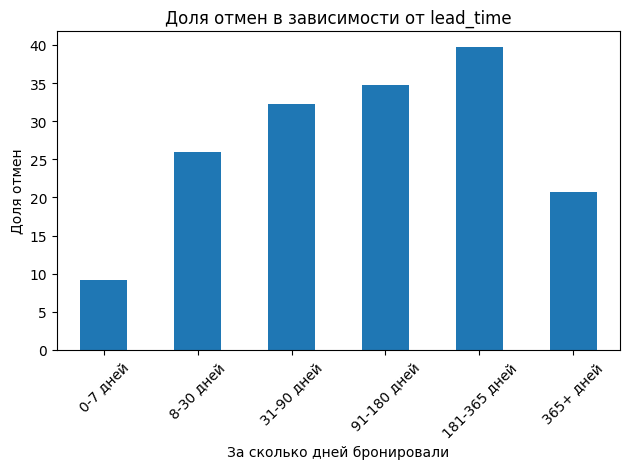

In [103]:
result['доля_отмен'].plot(kind='bar')
plt.title('Доля отмен в зависимости от lead_time')
plt.ylabel('Доля отмен')
plt.xlabel('За сколько дней бронировали')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Чем раньше сделано бронирование, тем выше доля его отмены.
0-7 дней < 10%
91-180 дней около 35%
Возможно необходимо сделать предоплату для тех кто бронирует ранее 90 дней